# Vectorizing Text: Bag of Words vs. TF-IDF

Models can't read words, only numbers. Both methods below turn each sentence into a row of numbers, one column per word in the vocabulary. Walkthrough of `src/analyze.py`.

In [1]:
import sys
sys.path.insert(0, '../src')

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import analyze

pd.set_option('display.max_colwidth', 100)

## The sentences

In [2]:
sentences = analyze.load_sentences()
pd.Series(sentences, index=[f'S{i+1}' for i in range(len(sentences))], name='sentence').to_frame()

,sentence
S1,Most shark attacks occur about 10 feet from the beach since that is where the people are
S2,the efficiency with which he paired the socks in the drawer was quite admirable
S3,carol drank the blood as if she were a vampire
S4,giving directions that the mountains are to the west only works when you can see them
S5,the sign said there was road work ahead so he decided to speed up
S6,the gruff old man sat in the back of the bait shop grumbling to himself as he scooped out a hand...


## Bag of Words

Count how many times each word appears in each sentence. Word order is thrown away, hence the "bag". The default tokenizer lowercases and drops one-character tokens like "a".

In [3]:
bow = analyze.vectorize(sentences, CountVectorizer())
print(bow.shape[0], 'sentences x', bow.shape[1], 'words')
bow

6 sentences x 71 words


,10,about,admirable,ahead,are,as,attacks,back,bait,beach,...,were,west,when,where,which,with,work,works,worms,you
S1,1,1,0,0,1,0,1,0,0,1,...,0,0,0,1,0,0,0,0,0,0
S2,0,0,1,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
S3,0,0,0,0,0,1,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
S4,0,0,0,0,1,0,0,0,0,0,...,0,1,1,0,0,0,0,1,0,1
S5,0,0,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
S6,0,0,0,0,0,1,0,1,1,0,...,0,0,0,0,0,0,0,0,1,0


In [4]:
analyze.top_terms(bow)

,top terms
S1,"the (2.00), 10 (1.00), about (1.00)"
S2,"the (3.00), admirable (1.00), drawer (1.00)"
S3,"as (1.00), blood (1.00), carol (1.00)"
S4,"the (2.00), are (1.00), can (1.00)"
S5,"ahead (1.00), decided (1.00), he (1.00)"
S6,"the (3.00), of (2.00), as (1.00)"


The most frequent words are mostly "the", "of", "as": common, but telling us little about what each sentence is *about*.

## TF-IDF

**Term frequency × inverse document frequency.** Same counts, but each word is scaled down by how many sentences contain it, so words that appear everywhere count for less and distinctive words stand out. Rows are also length-normalised so long sentences don't dominate.

In [5]:
tfidf = analyze.vectorize(sentences, TfidfVectorizer())
tfidf.round(2)

,10,about,admirable,ahead,are,as,attacks,back,bait,beach,...,were,west,when,where,which,with,work,works,worms,you
S1,0.26,0.26,0.00,0.00,0.21,0.00,0.26,0.00,0.00,0.26,...,0.00,0.00,0.00,0.26,0.00,0.00,0.00,0.00,0.00,0.00
S2,0.00,0.00,0.29,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.29,0.29,0.00,0.00,0.00,0.00
S3,0.00,0.00,0.00,0.00,0.00,0.29,0.00,0.00,0.00,0.00,...,0.36,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
S4,0.00,0.00,0.00,0.00,0.22,0.00,0.00,0.00,0.00,0.00,...,0.00,0.27,0.27,0.00,0.00,0.00,0.00,0.27,0.00,0.27
S5,0.00,0.00,0.00,0.29,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.29,0.00,0.00,0.00
S6,0.00,0.00,0.00,0.00,0.00,0.18,0.00,0.22,0.22,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.22,0.00


In [6]:
analyze.top_terms(tfidf)

,top terms
S1,"10 (0.26), about (0.26), attacks (0.26)"
S2,"the (0.39), admirable (0.29), drawer (0.29)"
S3,"blood (0.36), carol (0.36), drank (0.36)"
S4,"can (0.27), directions (0.27), giving (0.27)"
S5,"ahead (0.29), decided (0.29), road (0.29)"
S6,"of (0.44), the (0.29), back (0.22)"


Distinctive words now rank higher ("blood", "carol", "drank"; "road", "ahead"). But "the" still scores high in S2 and S6. With only 6 sentences, almost every word is rare, so IDF can barely tell "the" apart from anything else. IDF only really pays off on a bigger corpus.

In [7]:
pd.DataFrame({'bow count': bow['the'], 'tfidf weight': tfidf['the'].round(3)})

,bow count,tfidf weight
S1,2,0.228
S2,3,0.391
S3,1,0.158
S4,2,0.241
S5,1,0.129
S6,3,0.290


## Removing stop words

For a small corpus it helps to drop stop words explicitly.

In [8]:
tfidf_sw = analyze.vectorize(sentences, TfidfVectorizer(stop_words='english'))
analyze.top_terms(tfidf_sw)

,top terms
S1,"10 (0.38), attacks (0.38), beach (0.38)"
S2,"admirable (0.41), drawer (0.41), efficiency (0.41)"
S3,"blood (0.50), carol (0.50), drank (0.50)"
S4,"directions (0.45), giving (0.45), mountains (0.45)"
S5,"ahead (0.38), decided (0.38), road (0.38)"
S6,"bait (0.32), gruff (0.32), grumbling (0.32)"


## Which sentences are similar?

Once text is a vector, we can measure similarity with cosine similarity (1 = same words, 0 = nothing shared). With raw counts, shared function words like "the" create similarity that has nothing to do with meaning.

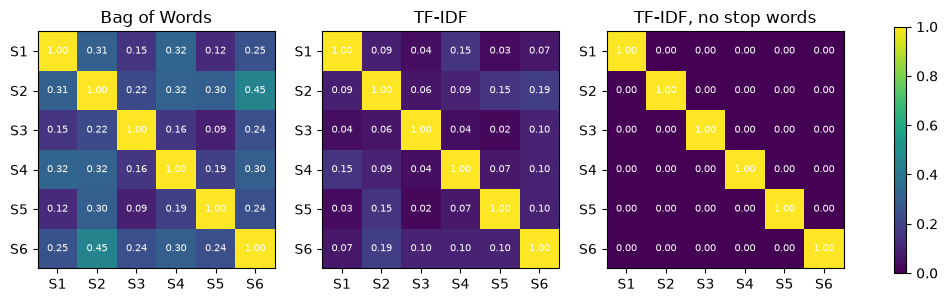

In [9]:
from sklearn.metrics.pairwise import cosine_similarity

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, df, name in zip(axes, (bow, tfidf, tfidf_sw), ('Bag of Words', 'TF-IDF', 'TF-IDF, no stop words')):
    sim = cosine_similarity(df)
    im = ax.imshow(sim, vmin=0, vmax=1, cmap='viridis')
    ax.set_xticks(range(len(df)), df.index); ax.set_yticks(range(len(df)), df.index)
    ax.set_title(name)
    for i in range(len(df)):
        for j in range(len(df)):
            ax.text(j, i, f'{sim[i, j]:.2f}', ha='center', va='center', color='white', fontsize=7)
fig.colorbar(im, ax=axes, shrink=0.8)
plt.show()